 cost liner regression


J(theta) = (1 / (2 * m)) * sum((h_theta(x) - y) ** 2)

h_theta(x) = theta_0 + theta_1 * X


Stepwise regression

theta_0 = theta_0 - (alpha / m) * sum((h_theta(x) - y))
theta_1 = theta_1 - (alpha / m) * sum((h_theta(x) - y) * X1)



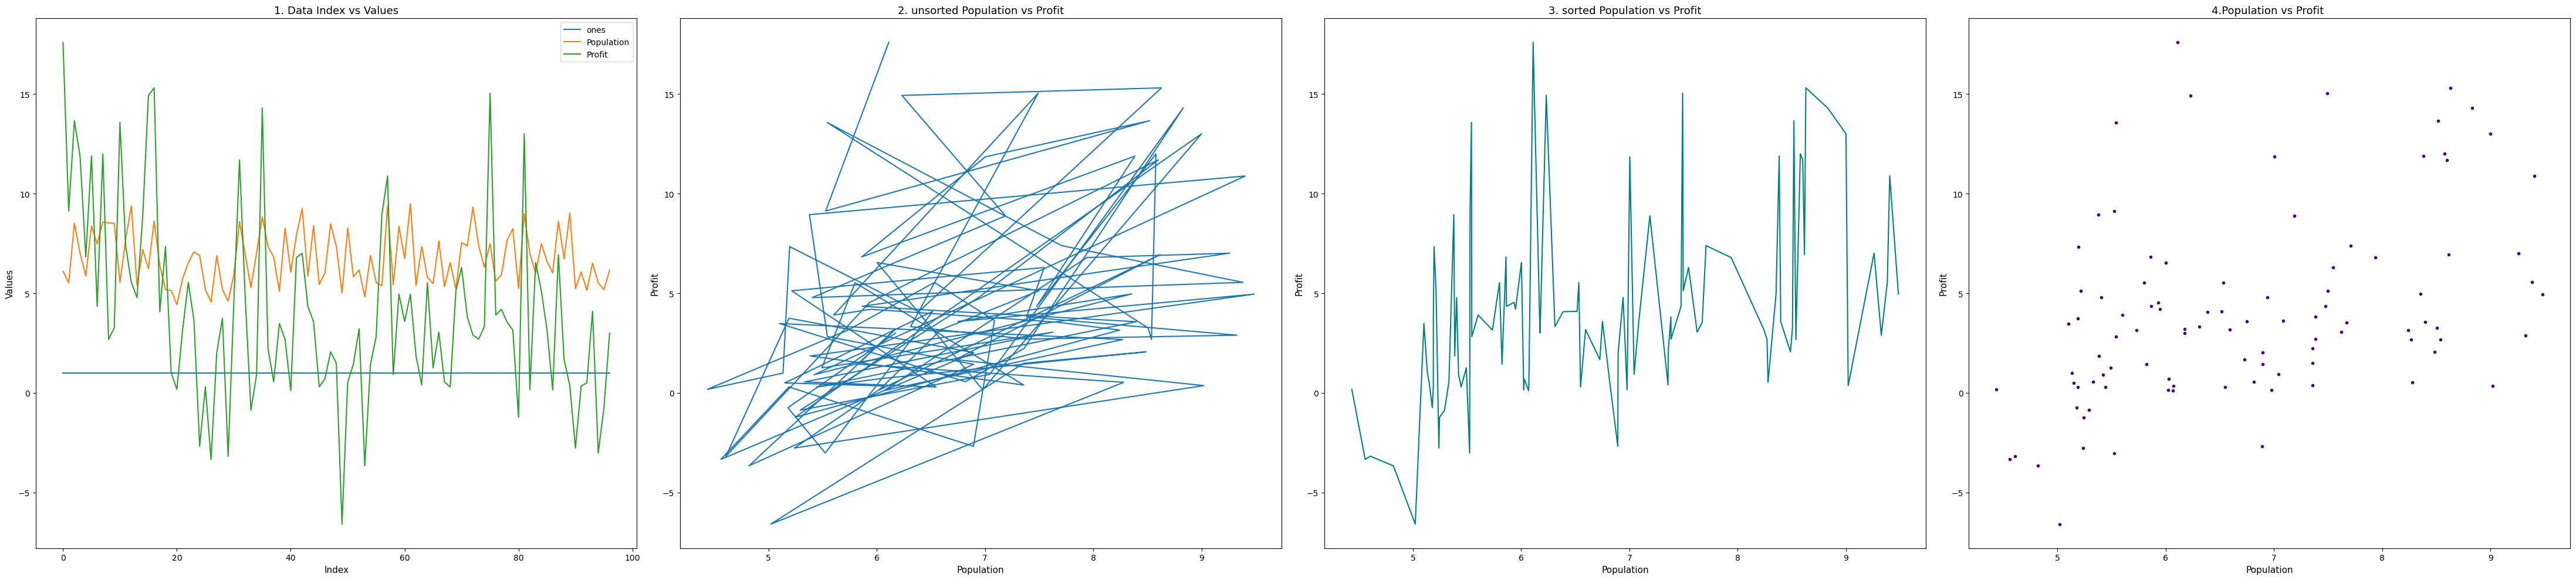

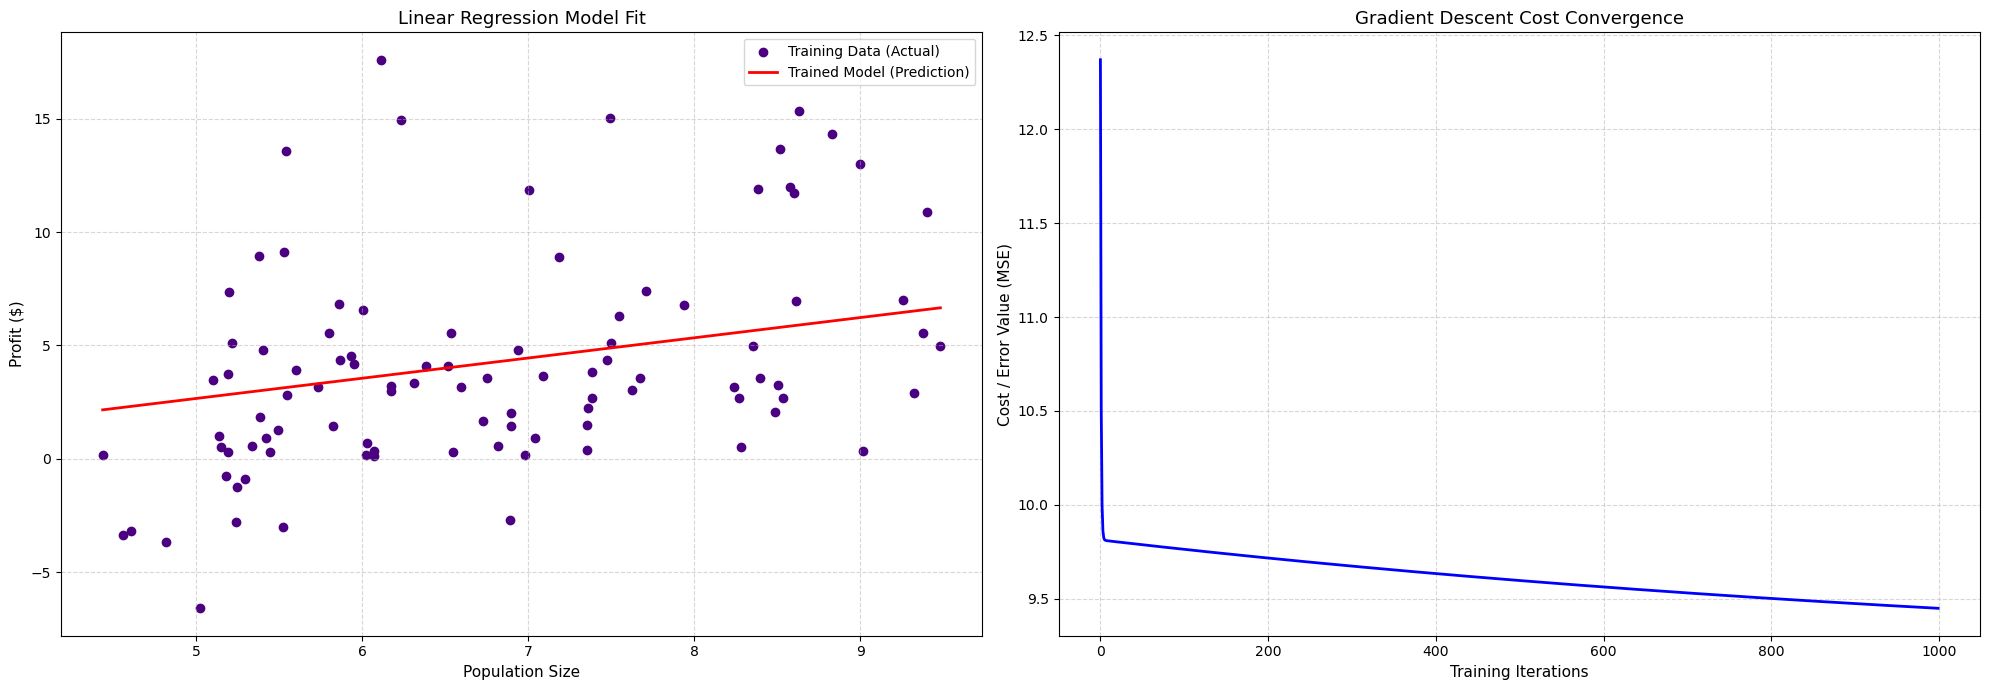

In [15]:


import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# _____________ read data_____________#
data = pd.read_csv('ex1data1.csv')

sorted_data = data.sort_values(by='Population')

# ____________add ones colmun________________#
data.insert(0, 'ones', 1)

# _________________ acesses    ________________#
columns = data.shape[1]  # length (columns number)

x = data.iloc[:, 0:columns-1]
y = data.iloc[:, columns-1:columns]

#_______________ convert to matrix _____________#
x = np.matrix(x.values)
y = np.matrix(y.values)
theta = np.matrix(np.array([0, 0]))  # theta0, theta1

# ____________________Cost function  in liner regression ____________________#
def mycost(x, y, theta):
    result = np.power((x * theta.T) - y, 2)
    m = len(x)
    return np.sum(result) / (2 * m)

# _________________ GD function  in Stepwise regression ____________#
def Stepwise_regression(x, y, theta, alpha, iters):
    temp = np.matrix(np.zeros(theta.shape))
    Parameter = int(theta.ravel().shape[1])
    cost = np.zeros(iters)
    
    for i in range(iters):
        error = (x * theta.T) - y
        
        for j in range(Parameter):
            term = np.multiply(error, x[:, j])
            temp[0, j] = theta[0, j] - ((alpha / len(x)) * np.sum(term))
            
        theta = temp
        cost[i] = mycost(x, y, theta)
        
    return theta, cost

# ______________________________ varibles ____________________#





alpha = 0.01
iters = 1000  # المحاولات

g, cost = Stepwise_regression(x, y, theta, alpha, iters)





#_________________draw data___________________#
sorted_data = data.sort_values(by='Population')

plt.figure(figsize=(44, 10))

plt.subplot(1, 4, 1)
data.plot(ax=plt.gca())
plt.title('1. Data Index vs Values', fontsize=13)
plt.xlabel('Index', fontsize=11)
plt.ylabel('Values', fontsize=11)

plt.subplot(1, 4, 2)
plt.plot(data['Population'], data['Profit'])
plt.title('2. unsorted Population vs Profit', fontsize=13)
plt.xlabel('Population', fontsize=11)
plt.ylabel('Profit', fontsize=11)

plt.subplot(1, 4, 3)
plt.plot(sorted_data['Population'], sorted_data['Profit'], color='Teal')
plt.title('3. sorted Population vs Profit', fontsize=13)
plt.xlabel('Population', fontsize=11)
plt.ylabel('Profit', fontsize=11)

plt.subplot(1, 4, 4)
plt.scatter(data['Population'], data['Profit'], color='Indigo', marker='.')
plt.title('4.Population vs Profit ', fontsize=13)
plt.xlabel('Population', fontsize=11)
plt.ylabel('Profit', fontsize=11)

plt.tight_layout()
plt.show()


#________________ best fit line ______________#


x_line = np.linspace(data.Population.min(), data.Population.max(), 100)



y_line= g[0, 0] + (g[0, 1] * x_line) # theta(x) = theta_0 + theta_1 * X




#  _______________________ draw regression ____________ # 

plt.figure(figsize=(20, 7))

plt.subplot(1, 2, 1)
plt.scatter(data['Population'], data['Profit'], color='Indigo', label='Training Data (Actual)')
plt.plot(x_line, y_line, color='Red', linewidth=2, label='Trained Model (Prediction)')
plt.xlabel('Population Size', fontsize=11)
plt.ylabel('Profit ($)', fontsize=11)
plt.legend()
plt.title('Linear Regression Model Fit', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(range(iters), cost, color='Blue', linewidth=2)
plt.xlabel('Training Iterations', fontsize=11)
plt.ylabel('Cost / Error Value (MSE)', fontsize=11)
plt.title('Gradient Descent Cost Convergence', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()



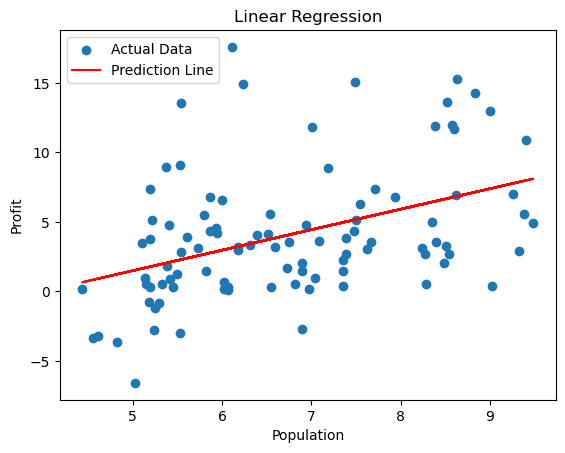

Prediction: 11.818234542628504
Slope: 1.4752157755491637
Intercept: -5.8843547639614595


In [27]:

import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


data = pd.read_csv('ex1data1.csv')



X = data[["Population"]]
y = data["Profit"]

model = LinearRegression()

model.fit(X, y)

value = float(input("Enter Population value: "))

prediction = model.predict(pd.DataFrame({"Population": [value]}))




plt.scatter(X["Population"], y, label="Actual Data")

plt.plot(X["Population"], model.predict(X), color="red", label="Prediction Line")

plt.xlabel("Population")
plt.ylabel("Profit")

plt.title("Linear Regression")

plt.legend()

plt.show()









print("Prediction:", prediction[0])
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

In [6]:
data

,Population,Profit
0,6.1101,17.59200
1,5.5277,9.13020
2,8.5186,13.66200
3,7.0032,11.85400
4,5.8598,6.82330
...,...,...
92,5.1506,0.50295
93,6.5164,4.09590
94,5.5240,-3.01920
95,5.1791,-0.74231


In [7]:
## ____________________sohw data___________________##
print(f'data = \n {data.head(10)}')
print('------------------------------'*3)
print(f'data.describe() = \n {data.describe()}')
print('------------------------------'*3)




data = 
    Population   Profit
0      6.1101  17.5920
1      5.5277   9.1302
2      8.5186  13.6620
3      7.0032  11.8540
4      5.8598   6.8233
5      8.3829  11.8860
6      7.4764   4.3483
7      8.5781  12.0000
8      8.5369   2.6841
9      8.5054   3.2630
------------------------------------------------------------------------------------------
data.describe() = 
        Population     Profit
count   97.000000  97.000000
mean     6.742382   4.062114
std      1.356731   4.737969
min      4.435400  -6.585000
25%      5.527700   0.709970
50%      6.547900   3.263000
75%      7.671900   5.550700
max      9.483900  17.592000
------------------------------------------------------------------------------------------


In [8]:
print("x=",x)
print('------------------------------'*3)


x= [[1.     6.1101]
 [1.     5.5277]
 [1.     8.5186]
 [1.     7.0032]
 [1.     5.8598]
 [1.     8.3829]
 [1.     7.4764]
 [1.     8.5781]
 [1.     8.5369]
 [1.     8.5054]
 [1.     5.5403]
 [1.     7.707 ]
 [1.     9.3814]
 [1.     5.4036]
 [1.     7.1884]
 [1.     6.2315]
 [1.     8.6291]
 [1.     6.3864]
 [1.     5.195 ]
 [1.     5.1337]
 [1.     4.4354]
 [1.     5.734 ]
 [1.     6.5322]
 [1.     7.087 ]
 [1.     6.892 ]
 [1.     5.1884]
 [1.     4.5594]
 [1.     6.8956]
 [1.     5.1888]
 [1.     4.607 ]
 [1.     5.9339]
 [1.     8.6001]
 [1.     6.9411]
 [1.     5.2917]
 [1.     7.0427]
 [1.     8.8303]
 [1.     7.3595]
 [1.     6.8174]
 [1.     5.1014]
 [1.     8.2703]
 [1.     6.068 ]
 [1.     7.9394]
 [1.     9.2589]
 [1.     5.8643]
 [1.     8.3972]
 [1.     5.4454]
 [1.     6.0271]
 [1.     8.4867]
 [1.     7.3572]
 [1.     5.0215]
 [1.     8.2797]
 [1.     5.823 ]
 [1.     6.1751]
 [1.     4.8196]
 [1.     6.8945]
 [1.     5.5437]
 [1.     5.3777]
 [1.     9.4036]
 [1.     5.

In [9]:
print("y=",y)





y= 0     17.59200
1      9.13020
2     13.66200
3     11.85400
4      6.82330
        ...   
92     0.50295
93     4.09590
94    -3.01920
95    -0.74231
96     3.00790
Name: Profit, Length: 97, dtype: float64


In [10]:
print(f" X= \n {x}")

print(f" X= \n {x.shape}")






 X= 
 [[1.     6.1101]
 [1.     5.5277]
 [1.     8.5186]
 [1.     7.0032]
 [1.     5.8598]
 [1.     8.3829]
 [1.     7.4764]
 [1.     8.5781]
 [1.     8.5369]
 [1.     8.5054]
 [1.     5.5403]
 [1.     7.707 ]
 [1.     9.3814]
 [1.     5.4036]
 [1.     7.1884]
 [1.     6.2315]
 [1.     8.6291]
 [1.     6.3864]
 [1.     5.195 ]
 [1.     5.1337]
 [1.     4.4354]
 [1.     5.734 ]
 [1.     6.5322]
 [1.     7.087 ]
 [1.     6.892 ]
 [1.     5.1884]
 [1.     4.5594]
 [1.     6.8956]
 [1.     5.1888]
 [1.     4.607 ]
 [1.     5.9339]
 [1.     8.6001]
 [1.     6.9411]
 [1.     5.2917]
 [1.     7.0427]
 [1.     8.8303]
 [1.     7.3595]
 [1.     6.8174]
 [1.     5.1014]
 [1.     8.2703]
 [1.     6.068 ]
 [1.     7.9394]
 [1.     9.2589]
 [1.     5.8643]
 [1.     8.3972]
 [1.     5.4454]
 [1.     6.0271]
 [1.     8.4867]
 [1.     7.3572]
 [1.     5.0215]
 [1.     8.2797]
 [1.     5.823 ]
 [1.     6.1751]
 [1.     4.8196]
 [1.     6.8945]
 [1.     5.5437]
 [1.     5.3777]
 [1.     9.4036]
 [1.    

In [11]:
print(f" theta= \n {theta}")

print(f" theta= \n {theta.shape}")


 theta= 
 [[0 0]]
 theta= 
 (1, 2)


In [12]:


print(f" Y= \n {y}")

print(f" Y= \n {y.shape}")


 Y= 
 0     17.59200
1      9.13020
2     13.66200
3     11.85400
4      6.82330
        ...   
92     0.50295
93     4.09590
94    -3.01920
95    -0.74231
96     3.00790
Name: Profit, Length: 97, dtype: float64
 Y= 
 (97,)


In [16]:
print(f"cost(j) =  {mycost(x,y,theta)} ")

cost(j) =  19.358848219372167 


In [ ]:
print('g = ' , g)

g =  [[-1.79002171  0.89089327]]


In [ ]:
print('cost  = ' , cost[0:50] )

cost  =  [12.36993547 10.49742587  9.99545474  9.860612    9.82411274  9.81395718
  9.81085863  9.80965073  9.80894957  9.80838444  9.80785603  9.80733774
  9.80682245  9.80630824  9.80579461  9.80528142  9.80476862  9.80425622
  9.80374421  9.80323258  9.80272134  9.80221049  9.80170002  9.80118993
  9.80068024  9.80017092  9.79966199  9.79915345  9.79864529  9.79813751
  9.79763012  9.79712311  9.79661648  9.79611024  9.79560438  9.7950989
  9.7945938   9.79408908  9.79358474  9.79308079  9.79257721  9.79207402
  9.7915712   9.79106877  9.79056671  9.79006503  9.78956374  9.78906282
  9.78856228  9.78806211]


In [ ]:
print('Cost = ', mycost(x, y, g))

Cost =  9.44912031292063


In [ ]:
x = np.linspace(data.Population.min(), data.Population.max(), 100)

print('x = \n',x)

x = 
 [4.4354     4.48639495 4.5373899  4.58838485 4.6393798  4.69037475
 4.7413697  4.79236465 4.8433596  4.89435455 4.94534949 4.99634444
 5.04733939 5.09833434 5.14932929 5.20032424 5.25131919 5.30231414
 5.35330909 5.40430404 5.45529899 5.50629394 5.55728889 5.60828384
 5.65927879 5.71027374 5.76126869 5.81226364 5.86325859 5.91425354
 5.96524848 6.01624343 6.06723838 6.11823333 6.16922828 6.22022323
 6.27121818 6.32221313 6.37320808 6.42420303 6.47519798 6.52619293
 6.57718788 6.62818283 6.67917778 6.73017273 6.78116768 6.83216263
 6.88315758 6.93415253 6.98514747 7.03614242 7.08713737 7.13813232
 7.18912727 7.24012222 7.29111717 7.34211212 7.39310707 7.44410202
 7.49509697 7.54609192 7.59708687 7.64808182 7.69907677 7.75007172
 7.80106667 7.85206162 7.90305657 7.95405152 8.00504646 8.05604141
 8.10703636 8.15803131 8.20902626 8.26002121 8.31101616 8.36201111
 8.41300606 8.46400101 8.51499596 8.56599091 8.61698586 8.66798081
 8.71897576 8.76997071 8.82096566 8.87196061 8.92295556 

In [ ]:
Equation_of_a_straight_line= g[0, 0] + (g[0, 1] * x)

print('Equation of a straight line = \n',Equation_of_a_straight_line)

Equation of a straight line = 
 [2.16144628 2.20687734 2.25230839 2.29773945 2.34317051 2.38860157
 2.43403262 2.47946368 2.52489474 2.57032579 2.61575685 2.66118791
 2.70661896 2.75205002 2.79748108 2.84291214 2.88834319 2.93377425
 2.97920531 3.02463636 3.07006742 3.11549848 3.16092954 3.20636059
 3.25179165 3.29722271 3.34265376 3.38808482 3.43351588 3.47894694
 3.52437799 3.56980905 3.61524011 3.66067116 3.70610222 3.75153328
 3.79696434 3.84239539 3.88782645 3.93325751 3.97868856 4.02411962
 4.06955068 4.11498174 4.16041279 4.20584385 4.25127491 4.29670596
 4.34213702 4.38756808 4.43299914 4.47843019 4.52386125 4.56929231
 4.61472336 4.66015442 4.70558548 4.75101654 4.79644759 4.84187865
 4.88730971 4.93274076 4.97817182 5.02360288 5.06903394 5.11446499
 5.15989605 5.20532711 5.25075816 5.29618922 5.34162028 5.38705134
 5.43248239 5.47791345 5.52334451 5.56877556 5.61420662 5.65963768
 5.70506874 5.75049979 5.79593085 5.84136191 5.88679296 5.93222402
 5.97765508 6.02308614 6.06851